# DSC Gelar Rasa 2026 — Automatic Waste Classification

Pipeline ini tidak memakai labeling manual. Model pretrained dijalankan **lokal** pada gambar kompetisi, kemudian:

1. MobileNetV2 ImageNet menghasilkan embedding dan skor objek.
2. Keyword semantic dari label bawaan pretrained model menghasilkan skor otomatis untuk 8 kelas sampah.
3. K-Means mengelompokkan embedding gambar.
4. Assignment optimal otomatis memasangkan cluster dengan kelas berdasarkan skor semantic agregat.
5. Model memprediksi test dan menyimpan `outputs/submission.csv`.

Handbook memperbolehkan pretrained model yang dijalankan oleh peserta, tetapi melarang API inference, LLM/VLM eksternal, dan dataset eksternal. Pipeline ini tidak mengirim gambar keluar dari notebook.

**Batasan:** karena train tidak memiliki label ground truth, akurasi 100% tidak dapat dibuktikan atau dijamin. Ini adalah pendekatan otomatis paling aman tanpa anotasi manual, bukan klaim akurasi sempurna.

In [1]:
# 1. Setup dan dataset
from pathlib import Path
import itertools, json, random
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from PIL import Image, UnidentifiedImageError

SEED = 42
random.seed(SEED); np.random.seed(SEED)
DATA_DIR = Path("Dataset DSC GelarRasa 2026")
TRAIN_DIR, TEST_DIR = DATA_DIR / "train", DATA_DIR / "test"
OUTPUT_DIR = Path("outputs")
EXTENSIONS = {".jpg", ".jpeg", ".png", ".bmp", ".webp"}
CLASSES = ["glass", "paper", "electronic", "metal", "plastic", "cardboard", "textile", "foodwaste"]
train_paths = sorted([p for p in TRAIN_DIR.rglob("*") if p.is_file() and p.suffix.lower() in EXTENSIONS])
test_paths = sorted([p for p in TEST_DIR.rglob("*") if p.is_file() and p.suffix.lower() in EXTENSIONS])
assert len(train_paths) == 1920 and len(test_paths) == 480

def valid(path):
    try:
        with Image.open(path) as im: im.verify()
        return True
    except (UnidentifiedImageError, OSError): return False
assert all(valid(p) for p in train_paths + test_paths)
print(f"Dataset valid: {len(train_paths)} train, {len(test_paths)} test")


Dataset valid: 1920 train, 480 test


In [2]:
# 2. Load pretrained classifier lokal
import tensorflow as tf
from tensorflow.keras.applications import MobileNetV2
from tensorflow.keras.applications.mobilenet_v2 import preprocess_input, decode_predictions

classifier = MobileNetV2(weights="imagenet", include_top=True, input_shape=(224,224,3))
classifier.trainable = False

def predict_imagenet(paths, batch_size=32):
    all_probs, all_top = [], []
    for start in range(0, len(paths), batch_size):
        batch_paths = paths[start:start+batch_size]
        images = []
        for p in batch_paths:
            im = tf.keras.utils.load_img(p, target_size=(224,224))
            images.append(tf.keras.utils.img_to_array(im))
        probs = classifier.predict(preprocess_input(np.asarray(images, dtype=np.float32)), verbose=0)
        all_probs.append(probs)
        all_top.extend(decode_predictions(probs, top=20))
    return np.concatenate(all_probs), all_top

all_paths = train_paths + test_paths
all_probs, all_top = predict_imagenet(all_paths)
print("ImageNet probability matrix:", all_probs.shape)


14536120/14536120 ━━━━━━━━━━━━━━━━━━━━ 14s 1us/step
35363/35363 ━━━━━━━━━━━━━━━━━━━━ 0s 2us/step
ImageNet probability matrix: (2400, 1000)


## 3. Semantic scoring otomatis

Skor berikut bukan label manual per gambar. Ia adalah aturan deterministik untuk mengagregasikan nama kelas bawaan ImageNet ke kategori kompetisi. Gambar tetap diproses oleh model lokal, tanpa API atau dataset tambahan.

In [3]:
CATEGORY_KEYWORDS = {
    "glass": {"glass", "wine_glass", "beer_glass", "goblet", "vase", "cup", "bottle"},
    "paper": {"paper", "newspaper", "notebook", "book", "envelope", "menu", "letter"},
    "electronic": {"screen", "monitor", "computer", "laptop", "keyboard", "mouse", "telephone", "cellular_telephone", "remote_control", "modem", "radio", "printer", "ipod"},
    "metal": {"can", "tin", "pan", "pot", "chain", "nail", "screw", "cleaver", "knife"},
    "plastic": {"plastic", "water_bottle", "bucket", "jug", "container", "toy", "ball", "pill_bottle"},
    "cardboard": {"carton", "box", "crate", "packet", "tray"},
    "textile": {"shirt", "jersey", "sweatshirt", "jean", "sock", "shoe", "wool", "coat", "backpack", "bag", "scarf", "pajama"},
    "foodwaste": {"banana", "apple", "orange", "lemon", "pizza", "hamburger", "hotdog", "broccoli", "cauliflower", "mushroom", "plate", "salad", "fruit"},
}

def semantic_scores(decoded_rows):
    scores = np.zeros((len(decoded_rows), len(CLASSES)), dtype=np.float32)
    for i, row in enumerate(decoded_rows):
        for _, label, probability in row:
            label = label.lower()
            for j, category in enumerate(CLASSES):
                if label in CATEGORY_KEYWORDS[category]:
                    scores[i, j] += float(probability)
    # Ensure every sample has a usable distribution, even if no top-20 label matches.
    row_sums = scores.sum(axis=1, keepdims=True)
    scores = np.where(row_sums > 0, scores / np.maximum(row_sums, 1e-8), 1.0 / len(CLASSES))
    return scores

semantic = semantic_scores(all_top)
print("Samples with semantic evidence:", int(np.sum(semantic.max(axis=1) > 1/len(CLASSES))), "/", len(all_paths))


Samples with semantic evidence: 2278 / 2400


In [4]:
# 4. Ensemble semantic score dengan embedding clustering
from sklearn.cluster import KMeans
from sklearn.preprocessing import normalize
from sklearn.metrics import silhouette_score

# Softmax probabilities are used as a compact ImageNet embedding.
train_embedding = normalize(np.log(all_probs[:len(train_paths)] + 1e-8))
test_embedding = normalize(np.log(all_probs[len(train_paths):] + 1e-8))
kmeans = KMeans(n_clusters=8, random_state=SEED, n_init=25)
train_cluster = kmeans.fit_predict(train_embedding)
test_cluster = kmeans.predict(test_embedding)
silhouette = silhouette_score(train_embedding, train_cluster, sample_size=min(1000, len(train_embedding)), random_state=SEED)

# Aggregate semantic evidence inside each cluster.
cluster_scores = np.zeros((8, 8), dtype=np.float64)
for cluster_id in range(8):
    members = np.where(train_cluster == cluster_id)[0]
    cluster_scores[cluster_id] = semantic[members].mean(axis=0) if len(members) else 0

# Find the one-to-one cluster/category assignment with maximum total evidence.
best_perm, best_value = None, -1
for perm in itertools.permutations(range(8)):
    value = sum(cluster_scores[c, perm[c]] for c in range(8))
    if value > best_value:
        best_value, best_perm = value, perm
auto_mapping = {cluster_id: CLASSES[best_perm[cluster_id]] for cluster_id in range(8)}

print("Silhouette:", round(float(silhouette), 5))
print("Automatic cluster mapping:", auto_mapping)
print(pd.Series(train_cluster).value_counts().sort_index().rename("count"))


c:\Users\Danu\anaconda3\Lib\site-packages\sklearn\cluster\_kmeans.py:1428: UserWarning: KMeans is known to have a memory leak on Windows with MKL, when there are less chunks than available threads. You can avoid it by setting the environment variable OMP_NUM_THREADS=8.
  warnings.warn(


Silhouette: 0.0567
Automatic cluster mapping: {0: 'glass', 1: 'plastic', 2: 'textile', 3: 'metal', 4: 'paper', 5: 'foodwaste', 6: 'cardboard', 7: 'electronic'}
0     66
1    500
2    213
3    303
4    321
5    108
6    217
7    192
Name: count, dtype: int64


Agreement semantic-vs-cluster: 0.5188
Agreement ini bukan akurasi ground truth karena train tidak memiliki label.


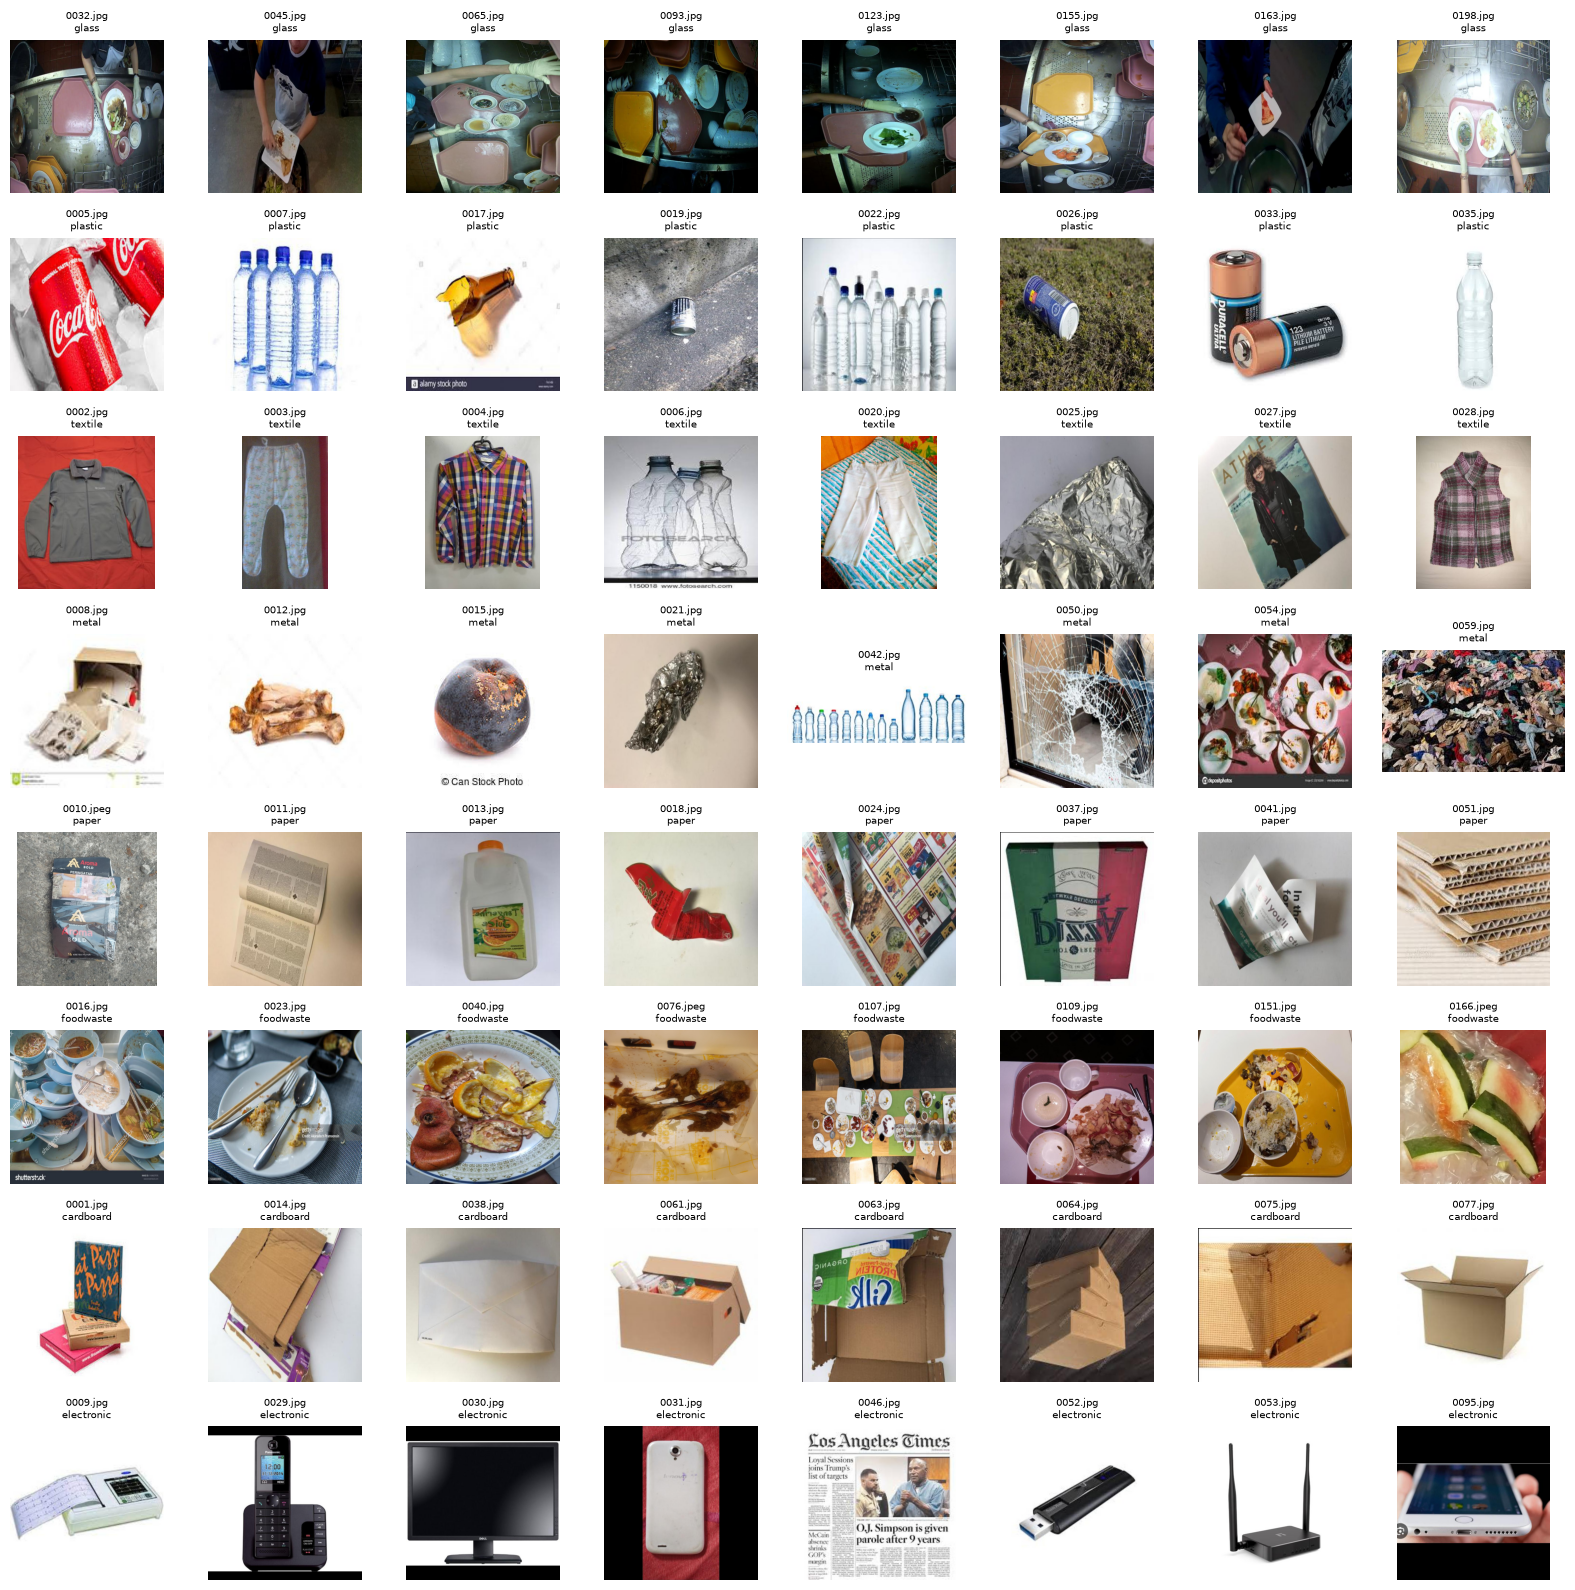

In [5]:
# 5. Audit ringkas tanpa labeling manual
train_semantic_labels = [CLASSES[int(np.argmax(semantic[i]))] for i in range(len(train_paths))]
auto_train_labels = [auto_mapping[int(c)] for c in train_cluster]
agreement = np.mean(np.array(train_semantic_labels) == np.array(auto_train_labels))
print("Agreement semantic-vs-cluster:", round(float(agreement), 4))
print("Agreement ini bukan akurasi ground truth karena train tidak memiliki label.")

fig, axes = plt.subplots(8, 8, figsize=(16,16))
for cluster_id, row_axes in enumerate(axes):
    ids = np.where(train_cluster == cluster_id)[0][:8]
    for ax in row_axes: ax.axis("off")
    for ax, idx in zip(row_axes, ids):
        ax.imshow(Image.open(train_paths[idx]).convert("RGB"))
        ax.set_title(f"{train_paths[idx].name}\n{auto_mapping[cluster_id]}", fontsize=7)
    row_axes[0].set_ylabel(f"C{cluster_id}", fontsize=10)
plt.tight_layout(); plt.show()


In [6]:
# 6. Prediksi test dan simpan submission
OUTPUT_DIR.mkdir(exist_ok=True)
predicted_labels = [auto_mapping[int(c)] for c in test_cluster]
submission = pd.DataFrame({"filename": [p.name for p in test_paths], "predicted_label": predicted_labels})
submission.to_csv(OUTPUT_DIR / "submission.csv", index=False)
pd.DataFrame({"filename": [p.name for p in train_paths], "cluster": train_cluster, "auto_label": [auto_mapping[int(c)] for c in train_cluster]}).to_csv(OUTPUT_DIR / "train_auto_labels.csv", index=False)
pd.DataFrame({"filename": [p.name for p in test_paths], "cluster": test_cluster, "predicted_label": predicted_labels}).to_csv(OUTPUT_DIR / "test_predictions.csv", index=False)
report = {"train_images": len(train_paths), "test_images": len(test_paths), "silhouette": float(silhouette), "agreement_not_accuracy": float(agreement), "automatic_mapping": auto_mapping, "warning": "No ground truth labels; 100% accuracy cannot be guaranteed."}
(OUTPUT_DIR / "run_report.json").write_text(json.dumps(report, indent=2), encoding="utf-8")
print(submission.head(10))
print("Saved:", OUTPUT_DIR / "submission.csv")


  filename predicted_label
0  001.jpg       cardboard
1  002.jpg           glass
2  003.jpg           glass
3  004.jpg         plastic
4  005.jpg           paper
5  006.jpg           metal
6  007.jpg           metal
7  008.jpg       cardboard
8  009.jpg           metal
9  010.jpg         plastic
Saved: outputs\submission.csv


## Kesimpulan

Notebook ini sepenuhnya otomatis dan tidak membutuhkan labeling manual. Ia memakai model pretrained lokal yang diizinkan handbook, bukan API atau dataset eksternal. Jika hasil masih rendah, penyebab utamanya adalah tidak adanya label train dan keterbatasan semantic label ImageNet terhadap kategori limbah—bukan sekadar pilihan algoritma.